In [ ]:
import tensorflow as tf
import numpy as np

In [ ]:
def construct_vision_tensor(image_path: str, max_resolution: int = 512) -> tf.Tensor:
    raw_bytes = tf.io.read_file(image_path)
    decoded_matrix = tf.image.decode_image(raw_bytes, channels=3, dtype=tf.float32)
    matrix_dimensions = tf.cast(tf.shape(decoded_matrix)[:-1], tf.float32)
    longest_edge = tf.reduce_max(matrix_dimensions)
    scale_multiplier = max_resolution / longest_edge
    target_dimensions = tf.cast(matrix_dimensions * scale_multiplier, tf.int32)
    scaled_matrix = tf.image.resize(decoded_matrix, target_dimensions)
    batched_tensor = tf.expand_dims(scaled_matrix, axis=0)
    normalized_pixels = batched_tensor * 255.0
    return tf.keras.applications.vgg19.preprocess_input(normalized_pixels)

In [ ]:
content_path = "/content/qiz.jpeg"
semantic_target = construct_vision_tensor(content_path)

In [ ]:
art_style_path = "/content/art1.jpeg"
aesthetic_target = construct_vision_tensor(art_style_path)

In [ ]:
class AestheticPerceptionModel(tf.keras.Model):
    def __init__(self, style_extraction_nodes, content_extraction_nodes):
        super(AestheticPerceptionModel, self).__init__()
        core_network = tf.keras.applications.VGG19(include_top=False, weights='imagenet')
        core_network.trainable = False
        self.style_nodes = style_extraction_nodes
        self.content_nodes = content_extraction_nodes
        self.split_index = len(style_extraction_nodes)
        routing_outputs = [core_network.get_layer(node).output
                           for node in (self.style_nodes + self.content_nodes)]
        self.perception_engine = tf.keras.Model(inputs=core_network.input, outputs=routing_outputs)
    def extract_spatial_correlations(self, feature_map):
        correlation_matrix = tf.linalg.einsum('bijc,bijd->bcd', feature_map, feature_map)
        map_shape = tf.shape(feature_map)
        spatial_area = tf.cast(map_shape[1] * map_shape[2], tf.float32)
        return correlation_matrix / spatial_area
    def call(self, input_tensor):
        raw_activations = self.perception_engine(input_tensor)
        style_activations = raw_activations[:self.split_index]
        content_activations = raw_activations[self.split_index:]
        processed_styles = [self.extract_spatial_correlations(act) for act in style_activations]
        return {
            'aesthetic_features': processed_styles,
            'semantic_features': content_activations
        }

In [ ]:

style_layers = [
    'block1_conv1',
    'block2_conv1',
    'block3_conv1',
    'block4_conv1',
    'block5_conv1'
]
content_layers = ['block4_conv2']

In [ ]:
nst_engine = AestheticPerceptionModel(style_layers, content_layers)

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
target_semantics = nst_engine(semantic_target)['semantic_features']

In [ ]:
target_aesthetics = nst_engine(aesthetic_target)['aesthetic_features']

In [ ]:
synthetic_canvas = tf.Variable(construct_vision_tensor(content_path))

In [ ]:
class SemanticPreservationMetric(tf.keras.losses.Loss):
    def __init__(self, name="semantic_loss", **kwargs):
        super(SemanticPreservationMetric, self).__init__(name=name, **kwargs)
        self.mse_calculator = tf.keras.losses.MeanSquaredError()

    def call(self, original_semantics, synthesized_semantics):
        raw_error = self.mse_calculator(original_semantics, synthesized_semantics)
        return raw_error

In [ ]:
class AestheticDeviationMetric(tf.keras.losses.Loss):
    def __init__(self, name="aesthetic_loss", **kwargs):
        super(AestheticDeviationMetric, self).__init__(name=name, **kwargs)
        self.mse_calculator = tf.keras.losses.MeanSquaredError()
    def call(self, target_grams, synthesized_grams):
        layer_errors = []
        for target_matrix, synth_matrix in zip(target_grams, synthesized_grams):
            layer_diff = self.mse_calculator(target_matrix, synth_matrix)
            layer_errors.append(layer_diff)
        accumulated_error = tf.add_n(layer_errors)
        total_layers = tf.cast(len(target_grams), tf.float32)
        return accumulated_error / total_layers

In [ ]:
class SpatialSmoothnessPenalty(tf.Module):
    def __init__(self, name="smoothness_penalty", **kwargs):
        super(SpatialSmoothnessPenalty, self).__init__(name=name, **kwargs)
    @tf.function
    def __call__(self, image_tensor):
        return tf.image.total_variation(image_tensor)

In [ ]:
class GlobalObjectiveManager:
    def __init__(self, config_weights):
        self.alpha = config_weights.get('semantic_weight', 1e4)
        self.beta = config_weights.get('aesthetic_weight', 1e-2)
        self.gamma = config_weights.get('smoothness_weight', 30)

        self.semantic_evaluator = SemanticPreservationMetric()
        self.aesthetic_evaluator = AestheticDeviationMetric()
        self.smoothness_evaluator = SpatialSmoothnessPenalty()

    def evaluate_total_loss(self, synthesized_features, synthesized_image, target_semantics, target_aesthetics):
        c_loss = self.semantic_evaluator(target_semantics, synthesized_features['semantic_features'])

        s_loss = self.aesthetic_evaluator(target_aesthetics, synthesized_features['aesthetic_features'])

        tv_loss = self.smoothness_evaluator(synthesized_image)
        total_objective = (self.alpha * c_loss) + (self.beta * s_loss) + (self.gamma * tv_loss)
        return total_objective

In [ ]:
optimization_configs = {
    'semantic_weight': 1.0,
    'aesthetic_weight': 1000000.0,
    'smoothness_weight': 0.001
}

In [ ]:
loss_manager = GlobalObjectiveManager(optimization_configs)

In [ ]:
import time

In [ ]:
class StyleTransferOrchestrator:
    def __init__(self, perception_model, objective_manager, target_semantics, target_aesthetics, learning_rate=0.01):
        self.vision_engine = perception_model
        self.loss_compiler = objective_manager
        self.target_semantics = target_semantics
        self.target_aesthetics = target_aesthetics

        self.optimizer = tf.keras.optimizers.Adam(
            learning_rate=learning_rate,
            beta_1=0.99,
            epsilon=1e-1
        )

    def _constrain_pixel_space(self, image_variable):
        mean = np.array([103.939, 116.779, 123.68])
        clipped_tensor = tf.clip_by_value(image_variable, -mean, 255.0 - mean)
        image_variable.assign(clipped_tensor)

    @tf.function
    def execute_optimization_step(self, synthetic_canvas):
        with tf.GradientTape() as tape:
            current_features = self.vision_engine(synthetic_canvas)
            total_objective = self.loss_compiler.evaluate_total_loss(
                current_features,
                synthetic_canvas,
                self.target_semantics,
                self.target_aesthetics
            )
        pixel_gradients = tape.gradient(total_objective, synthetic_canvas)
        self.optimizer.apply_gradients([(pixel_gradients, synthetic_canvas)])
        self._constrain_pixel_space(synthetic_canvas)
        return total_objective

    def run_training_cycle(self, synthetic_canvas, epochs=1000):
        print("Optimization is starting...")
        import time
        start_time = time.time()
        for step in range(1, epochs + 1):
            current_loss = self.execute_optimization_step(synthetic_canvas)

            if step % 100 == 0:
                elapsed_time = time.time() - start_time
                loss_value = float(tf.reduce_sum(current_loss).numpy())
                print(f"Epoch {step:04d}/{epochs} | Loss: {loss_value:.2f} | Time: {elapsed_time:.1f} second")
                start_time = time.time()

        print("Optimization finished!")
        return synthetic_canvas

In [ ]:

training_orchestrator = StyleTransferOrchestrator(
    perception_model=nst_engine,
    objective_manager=loss_manager,
    target_semantics=target_semantics,
    target_aesthetics=target_aesthetics,
    learning_rate=2.0
)

In [ ]:
final_artwork = training_orchestrator.run_training_cycle(
    synthetic_canvas=synthetic_canvas,
    epochs=1000
)

Optimizasyon başlıyor...
Epoch 0100/1000 | Loss: 172671929155584.00 | Zaman: 11.3 saniye
Epoch 0200/1000 | Loss: 75125982494720.00 | Zaman: 6.9 saniye
Epoch 0300/1000 | Loss: 33684086325248.00 | Zaman: 6.9 saniye
Epoch 0400/1000 | Loss: 18841006505984.00 | Zaman: 7.0 saniye
Epoch 0500/1000 | Loss: 12697519259648.00 | Zaman: 7.1 saniye
Epoch 0600/1000 | Loss: 9541827690496.00 | Zaman: 7.1 saniye
Epoch 0700/1000 | Loss: 7718188351488.00 | Zaman: 7.2 saniye
Epoch 0800/1000 | Loss: 6571229184000.00 | Zaman: 7.3 saniye
Epoch 0900/1000 | Loss: 5788332982272.00 | Zaman: 7.4 saniye
Epoch 1000/1000 | Loss: 5217687437312.00 | Zaman: 7.5 saniye
Optimizasyon bitti!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
def render_and_save_artwork(tensor_signal, output_filename="final_fusi_artwork.jpg"):
    pixel_array = tensor_signal.numpy()
    if len(pixel_array.shape) == 4:
        pixel_array = np.squeeze(pixel_array, axis=0)
    pixel_array[:, :, 0] += 103.939
    pixel_array[:, :, 1] += 116.779
    pixel_array[:, :, 2] += 123.680
    pixel_array = pixel_array[:, :, ::-1]
    standardized_image = np.clip(pixel_array, 0, 255).astype('uint8')
    plt.figure(figsize=(12, 12))
    plt.imshow(standardized_image)
    plt.axis('off')
    plt.show()
    tf.keras.utils.save_img(output_filename, standardized_image)
    print(f"'{output_filename}' is file name.")
    return standardized_image

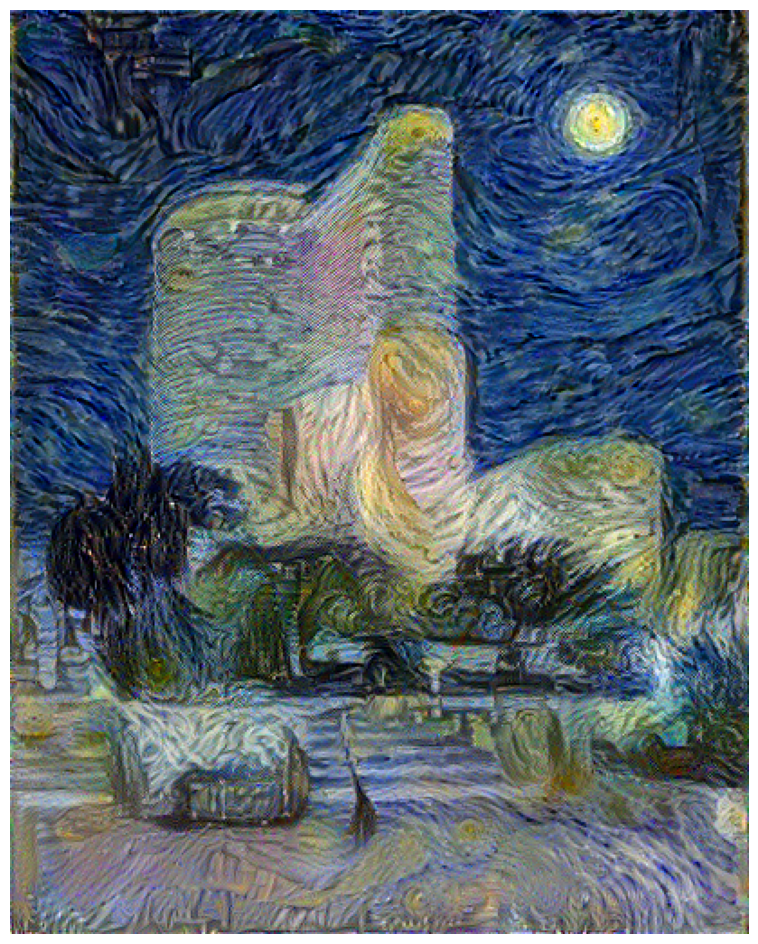

'baku_nst.jpg' adı ile yazildi


In [ ]:
processed_matrix = render_and_save_artwork(final_artwork, output_filename="baku_nst.jpg")

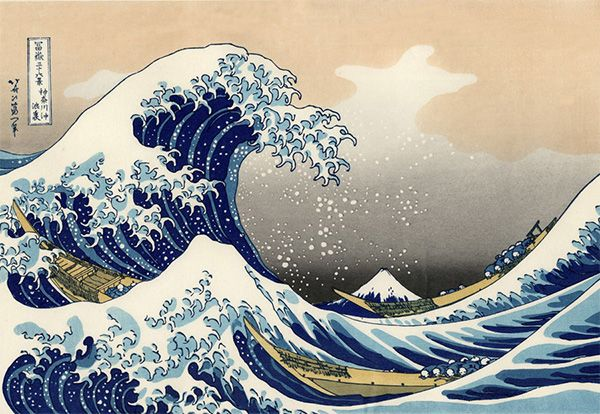

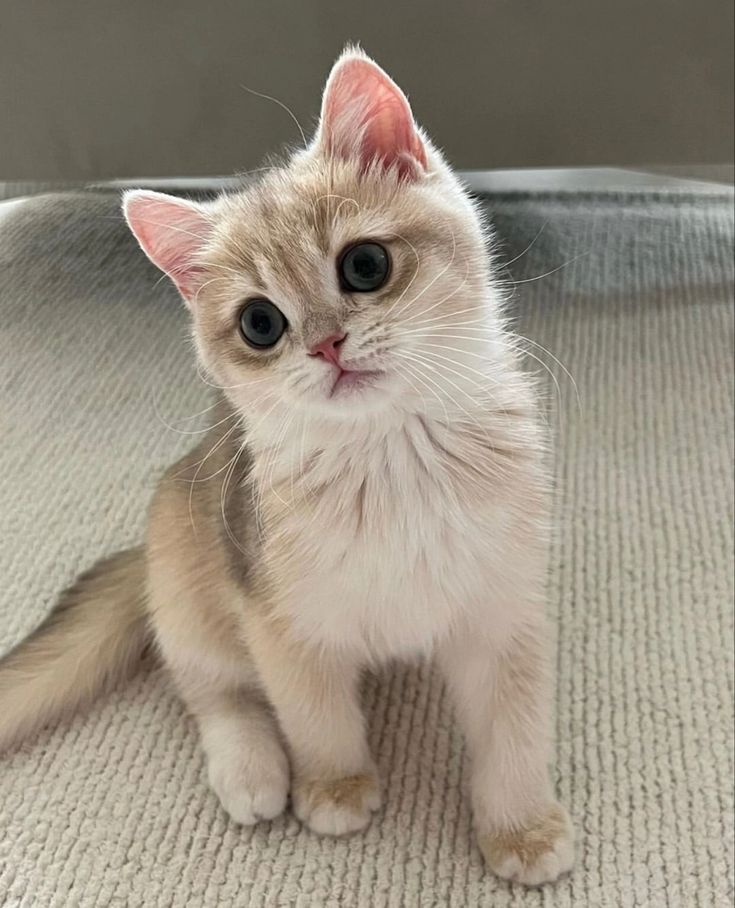

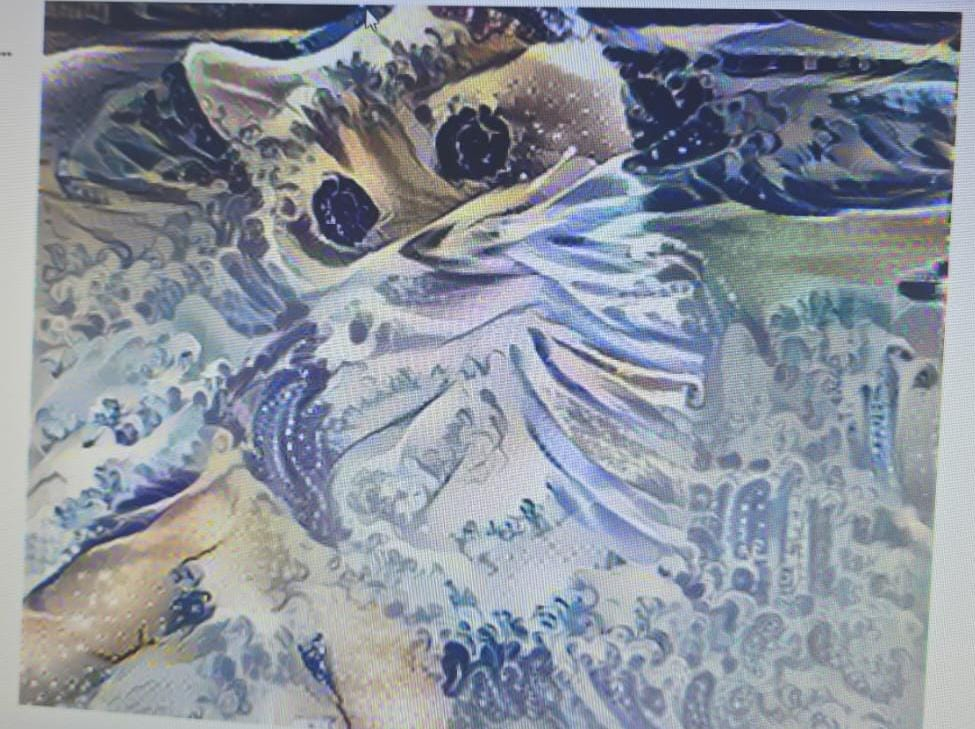